In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

In [7]:
df = pd.read_csv('../../data/processed/reg-szn/player_data_merged.csv')

df = df[df['advanced_MP'] >= 500]
df.shape

(379, 233)

In [ ]:
target = 'advanced_WS'

categories = [
    'per-game_FG', 'per-game_FGA', 'per-game_FG%', 'per-game_3P', 'per-game_3PA', 'per-game_3P%',
    'per-game_2P', 'per-game_2PA', 'per-game_2P%', 'per-game_eFG%', 'per-game_FT', 'per-game_FTA', 'per-game_FT%',
    'per-game_ORB', 'per-game_DRB', 'per-game_TRB', 'per-game_AST', 'per-game_STL', 'per-game_BLK',
    'per-game_TOV', 'per-game_PF', 'per-game_PTS',
]

In [ ]:
# I want to compare Advanced winshare with certain statistical per-game categories,
# to see which categories are most predictive of winshare. Via R^2

results = []
for col in categories:
    sub = df[[col, target]].dropna()
    model = LinearRegression().fit(sub[[col]], sub[target])
    r2 = model.score(sub[[col]], sub[target])
    results.append((col.replace('per-game_', ''), r2))

r2_df = pd.DataFrame(results, columns=['category', 'r2']).sort_values('r2', ascending=False)
r2_df

,category,r2
0,FG,0.373441
6,2P,0.367081
21,PTS,0.354653
15,TRB,0.318368
14,DRB,0.315750
11,FTA,0.304296
10,FT,0.300127
7,2PA,0.291787
1,FGA,0.246604
2,FG%,0.205591


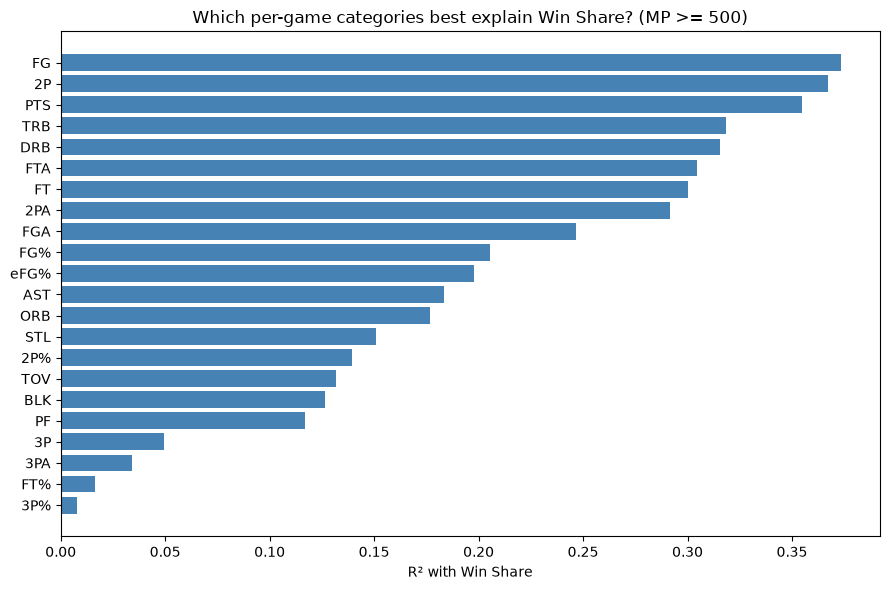

In [ ]:
plt.figure(figsize=(9, 6))
plt.barh(r2_df['category'], r2_df['r2'], color='steelblue')
plt.gca().invert_yaxis()
plt.xlabel('R² with Win Share')
plt.title('Which per-game categories best explain Win Share? (MP >= 500)')
plt.tight_layout()
plt.show()

# Really interesting how anything related to 3P doesn't have a big of win share as possible.

In [11]:
X = df[categories].dropna()
y = df.loc[X.index, target]

multi_model = LinearRegression().fit(X, y)
print('Combined R^2 using all categories:', multi_model.score(X, y))

Combined R^2 using all categories: 0.7727892049470068
